# Learn the Verified CD8+ T-cell Exhaustion Triage

> **This notebook uses simulated data. Its results are not biological evidence.**

**Audience:** a software engineer or first-time single-cell analyst who wants to understand and
defend the project rather than merely run it.

**Prerequisites:** basic Python and a willingness to read small tables. No prior immunology or
statistics course is assumed. Install the project once with `uv sync --extra dev`.

**Learning goals:** by the end, you can explain:

- what single-cell RNA counts, donors, marker genes, CD8+ cells, and exhaustion mean;
- why the donor—not the cell—is the independent statistical unit;
- how to read the UMAP, violin, volcano, robustness, and reviewer outputs;
- why this workflow says **verified/corroborated**, never wet-lab **validated**;
- how to replace the simulated input with the organizer's real `.h5ad` file safely.


## The project contract

**Question.** Within CD8+ T cells, is the score over `PDCD1, HAVCR2, LAG3, TOX, TIGIT, ENTPD1`
higher in condition B than A, and which subtype has the largest donor-aware increase?

**Pre-registered choices.** We lock the gene panels, CD8 gate, A/B contrast, donor unit, FDR rule,
and Leiden resolutions before seeing the answer. This prevents us from moving the goalposts after
looking at the result.

**Verification rule.** A fast per-cell hit is `VERIFIED` only if its direction agrees with
donor-level pseudobulk, pseudobulk FDR is below 0.05, and a human-auditable PubMed/Open Targets
record passes. Even then, it is computational corroboration—not qPCR, flow cytometry, or a
functional assay.


## Roadmap

1. Learn the ten essential biology/data terms.
2. Inspect an AnnData object and select the valid analysis branch.
3. See why thousands of cells are not thousands of independent experiments.
4. Run the full deterministic demo.
5. Read each required deliverable using a repeatable interpretation checklist.
6. Audit per-cell hits against donor pseudobulk and external evidence.
7. Practice the claim, limitations, and real-data handoff.

Expected time: about 60–90 minutes, including the exercises.


## Biology and data in ten terms

| Term | Software-engineer translation |
|---|---|
| Cell | One measured biological unit; here, one row of the matrix. |
| Gene | A named feature/column whose RNA abundance is measured. |
| Count | How many RNA molecules/reads were observed; sparse, noisy, and integer-valued. |
| scRNA-seq | A gene-expression matrix that keeps cells separate rather than averaging tissue. |
| T cell | An immune cell; CD8 and CD4 are major branches with different roles. |
| Marker gene | A gene used as evidence for a cell identity or state. |
| CD8 gate | Our operational rule: `(CD8A or CD8B positive) and CD4 zero` on raw counts. |
| Subtype/state | A finer CD8 grouping such as memory-like, cytotoxic, or exhausted. |
| Exhaustion | A state associated with persistent stimulation and reduced function; RNA markers are indirect evidence. |
| Donor | The independent person/animal/sample. Many cells from one donor remain correlated. |

Important: a zero RNA count can be **dropout**, not true biological absence. The CD8 gate is an
auditable operational rule, not perfect knowledge.


In [18]:
from __future__ import annotations

from pathlib import Path
import json

import anndata as ad
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, Markdown, display
from scipy import stats

from tcell_exhaustion.data import audit_input
from tcell_exhaustion.demo import demo_config, write_demo_h5ad
from tcell_exhaustion.pipeline import run_pipeline

PROJECT_ROOT = next(
    candidate
    for candidate in (Path.cwd().resolve(), *Path.cwd().resolve().parents)
    if (candidate / "pyproject.toml").is_file()
)
DATA_PATH = PROJECT_ROOT / "data" / "tutorial_demo.h5ad"
OUTPUT_DIR = PROJECT_ROOT / "output" / "notebook_demo"
EVIDENCE_PATH = PROJECT_ROOT / "evidence" / "literature_evidence.csv"
SEED = 42

print(f"Project root: {PROJECT_ROOT}")
print(f"Python seed: {SEED}")


Project root: C:\Users\miqba\projects\claude-science-hackathon-learning-plan
Python seed: 42


## Step 1 — Generate a dataset whose answer we know

The demo has six independent donors in A and six in B, four CD8 states, CD4 decoy cells, raw
integer counts, and donor-to-donor variability. We deliberately inject the largest B-condition
increase into the terminally exhausted population. If the workflow returns something else, we
debug the workflow rather than invent a story.


In [19]:
write_demo_h5ad(DATA_PATH, seed=SEED)
config = demo_config(DATA_PATH, OUTPUT_DIR, seed=SEED)
adata = ad.read_h5ad(DATA_PATH)

display(pd.DataFrame({
    "cells": [adata.n_obs],
    "genes": [adata.n_vars],
    "conditions": [adata.obs[config.condition_key].nunique()],
    "donors": [adata.obs[config.donor_key].nunique()],
    "known_headline": [adata.uns["simulation_truth"]["headline_subtype"]],
}))


,cells,genes,conditions,donors,known_headline
0,648,118,2,12,terminally_exhausted


### AnnData for software engineers

Think of AnnData as a versioned analysis object:

- `X`: the cell × gene matrix used for the current representation;
- `obs`: row metadata (condition, donor, labels);
- `var`: column metadata (gene symbols);
- `layers['counts']`: preserved raw evidence;
- `obsm`: derived coordinates such as PCA or UMAP;
- `uns`: provenance and other unstructured metadata.

Raw counts and normalized values have different jobs. We normalize for comparability and plots;
we sum **raw integer counts** for pseudobulk inference.


In [20]:
display(adata.obs.head(3))
display(adata.var.loc[["CD8A", "CD4", "PDCD1", "TOX"]])
print("X shape:", adata.X.shape)
print("Raw count layer dtype:", adata.layers["counts"].dtype)
print("Available derived coordinate keys before analysis:", list(adata.obsm))


,condition,donor,cell_type,subtype,true_subtype,is_simulated
cell_id,,,,,,
sim_cell_00001,A,A_donor_01,CD8_T,naive_memory,naive_memory,True
sim_cell_00002,A,A_donor_01,CD8_T,naive_memory,naive_memory,True
sim_cell_00003,A,A_donor_01,CD8_T,naive_memory,naive_memory,True


,gene_symbol,is_mito,is_exhaustion_panel,is_marker
gene_symbol,,,,
CD8A,CD8A,False,False,True
CD4,CD4,False,False,True
PDCD1,PDCD1,False,True,True
TOX,TOX,False,True,True


X shape: (648, 118)
Raw count layer dtype: int32
Available derived coordinate keys before analysis: []


## Step 2 — Day-1 audit chooses the statistical branch

The code does not guess. It verifies raw integer counts, unique gene symbols, condition labels,
donor replication, and required genes. It then chooses one of four declared branches:

- `donor_aware`: condition comparison and reviewer loop are valid;
- `exploratory_no_donor`: cell-level results only, with a pseudoreplication warning;
- `marker_fallback`: one condition, so only descriptive subtype patterns are defensible;
- `blocked`: missing or invalid evidence stops the run.


In [21]:
audit = audit_input(adata, config)
display(pd.Series(audit.to_dict(), name="observed value").to_frame())
assert audit.decision == "donor_aware"


,observed value
branch,donor_aware
reasons,[Both configured conditions and sufficient don...
warnings,[]
n_cells,648
n_genes,118
condition_counts,"{'A': 324, 'B': 324}"
donors_per_condition,"{'A': 6, 'B': 6}"
missing_genes,[]
counts_layer,counts
raw_counts_valid,True


## Step 3 — The pseudoreplication trap

Suppose four A donors and four B donors each contribute 100 correlated cells. A cell-level test
pretends `n=800`; the honest test sees `n=8`. The next example gives B only a tiny shift while
preserving large donor effects. Predict which p-value will look more impressive before running it.


In [22]:
rng = np.random.default_rng(SEED)
donor_offsets = np.array([-1.5, -0.5, 0.5, 1.5])
cells_a = np.concatenate([rng.normal(offset, 0.25, 100) for offset in donor_offsets])
cells_b = np.concatenate([rng.normal(offset + 0.15, 0.25, 100) for offset in donor_offsets])
donor_means_a = cells_a.reshape(4, 100).mean(axis=1)
donor_means_b = cells_b.reshape(4, 100).mean(axis=1)

cell_p = stats.ttest_ind(cells_b, cells_a, equal_var=False).pvalue
donor_p = stats.ttest_ind(donor_means_b, donor_means_a, equal_var=False).pvalue
pd.DataFrame({
    "analysis": ["incorrect: cells independent", "correct: donor means"],
    "sample_size_per_condition": [len(cells_a), len(donor_means_a)],
    "p_value": [cell_p, donor_p],
})


,analysis,sample_size_per_condition,p_value
0,incorrect: cells independent,400,0.090985
1,correct: donor means,4,0.885547


### Exercise 1 — identify the true sample size

There are 800 cell measurements above, but how many independent biological units are there?

Write your answer before revealing the scaffold below. Then explain why adding more cells from the
same donors improves measurement precision but does not create new biological replicates.


In [23]:
# Answer scaffold — replace the text with your own explanation.
exercise_1 = {
    "independent_units_total": 8,
    "why": "There are four donors in A and four in B; cells within a donor share biology.",
}
exercise_1


{'independent_units_total': 8,
 'why': 'There are four donors in A and four in B; cells within a donor share biology.'}

## Step 4 — Run the complete registered workflow

This single call performs the same package code used by the command line. It writes the audit,
analysis contract, QC table, annotated object, four required deliverables, per-cell DE,
pseudobulk DE, reviewer table, methods, report, walkthrough script, and checksum manifest.

It can take roughly 20–40 seconds because UMAP, Leiden, and PyDESeq2 are real computations.


In [24]:
run = run_pipeline(config, evidence_path=EVIDENCE_PATH)
pd.Series(run.to_dict(), name="run result").to_frame()


,run result
output_dir,C:\Users\miqba\projects\claude-science-hackath...
branch,donor_aware
headline_subtype,terminally_exhausted
headline_significant,True
robust,True
simulated,True
artifacts,[C:\Users\miqba\projects\claude-science-hackat...


## Step 5 — Quality control

**How to read it:** look for impossible values, extreme tails, and whether a threshold removes one
condition or donor disproportionately. Thresholds are dataset-specific; `200 genes` is not a law
of nature. The demo uses a small targeted gene universe, so its registered minimum is 10.

**Prediction:** simulated cells should form compact distributions and most CD8 cells should pass.


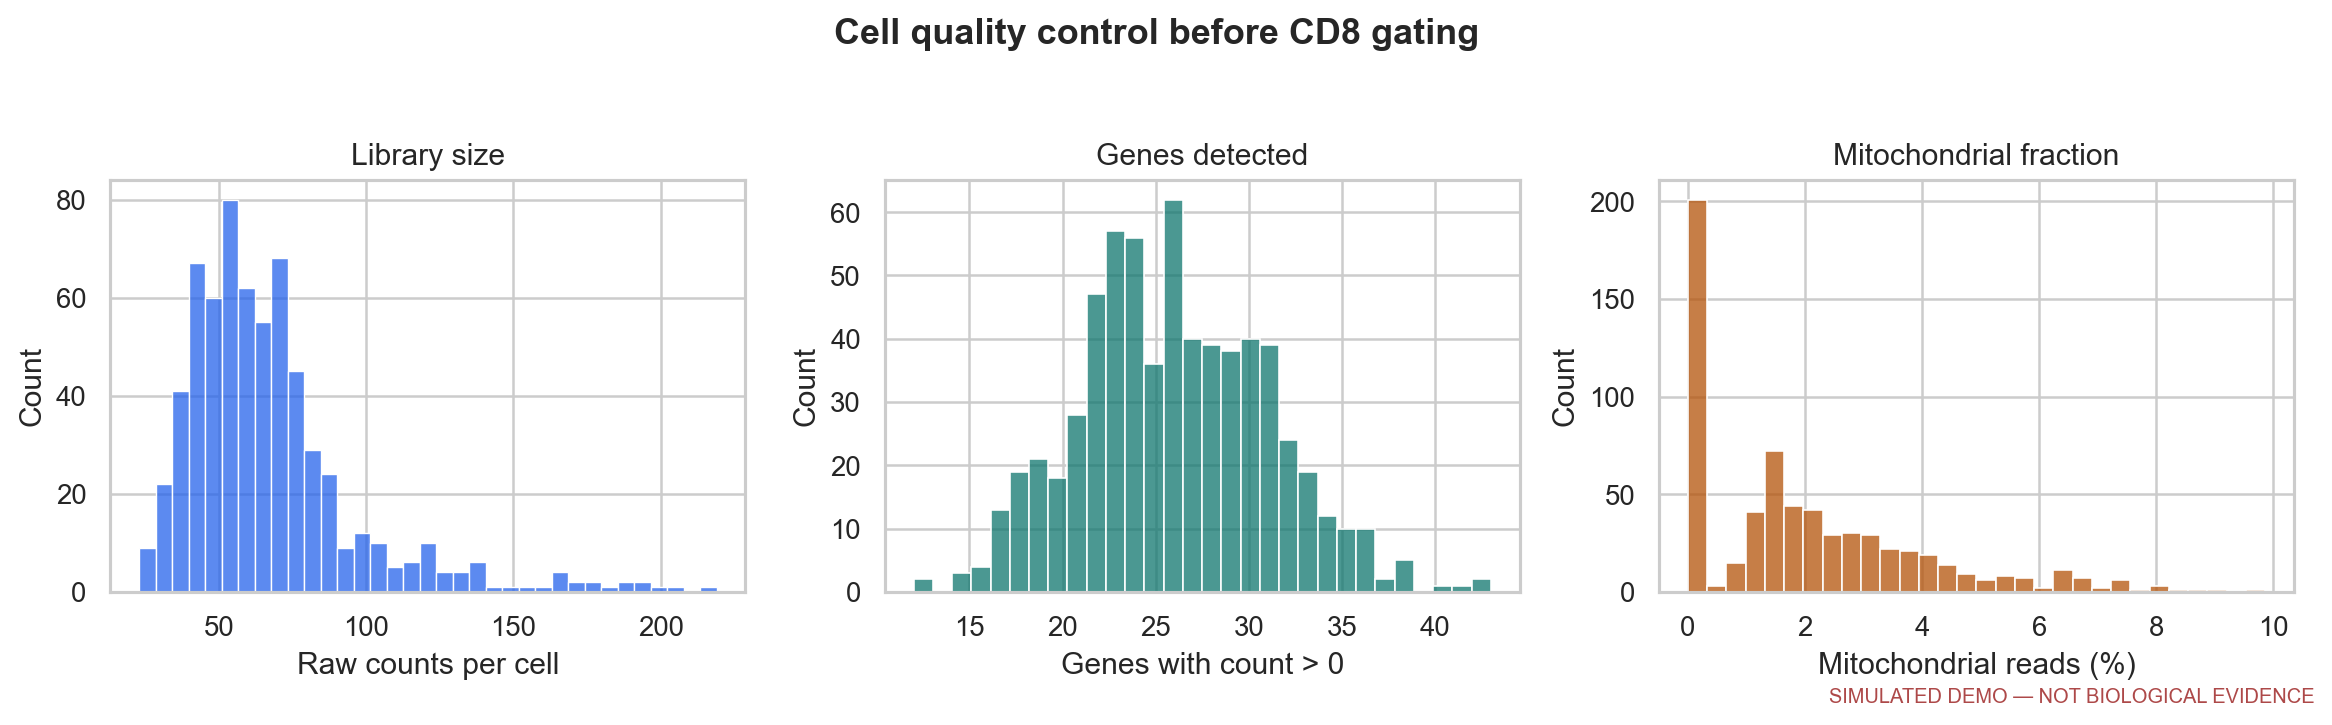

,fraction_true
qc_pass,1.00000
cd8_gate_pass,0.87037
analysis_pass,0.87037


In [25]:
display(Image(filename=OUTPUT_DIR / "figures" / "01_qc.png", width=950))
qc = pd.read_csv(OUTPUT_DIR / "tables" / "cell_qc_and_gate.csv")
qc[["qc_pass", "cd8_gate_pass", "analysis_pass"]].mean().rename("fraction_true").to_frame()


## Step 6 — Annotated UMAP (deliverable 1)

UMAP preserves local neighborhoods approximately. It is useful for asking whether marker-defined
states form coherent neighborhoods and whether condition is completely confounded with a region.
It does **not** prove discrete cell types, and distance between far-away islands has no simple
biological meaning.

**Good sign:** labels align with marker scores and both conditions contribute to each subtype.
**Red flag:** a label is justified only by where it sits on the UMAP, or an island contains one
donor/batch only.


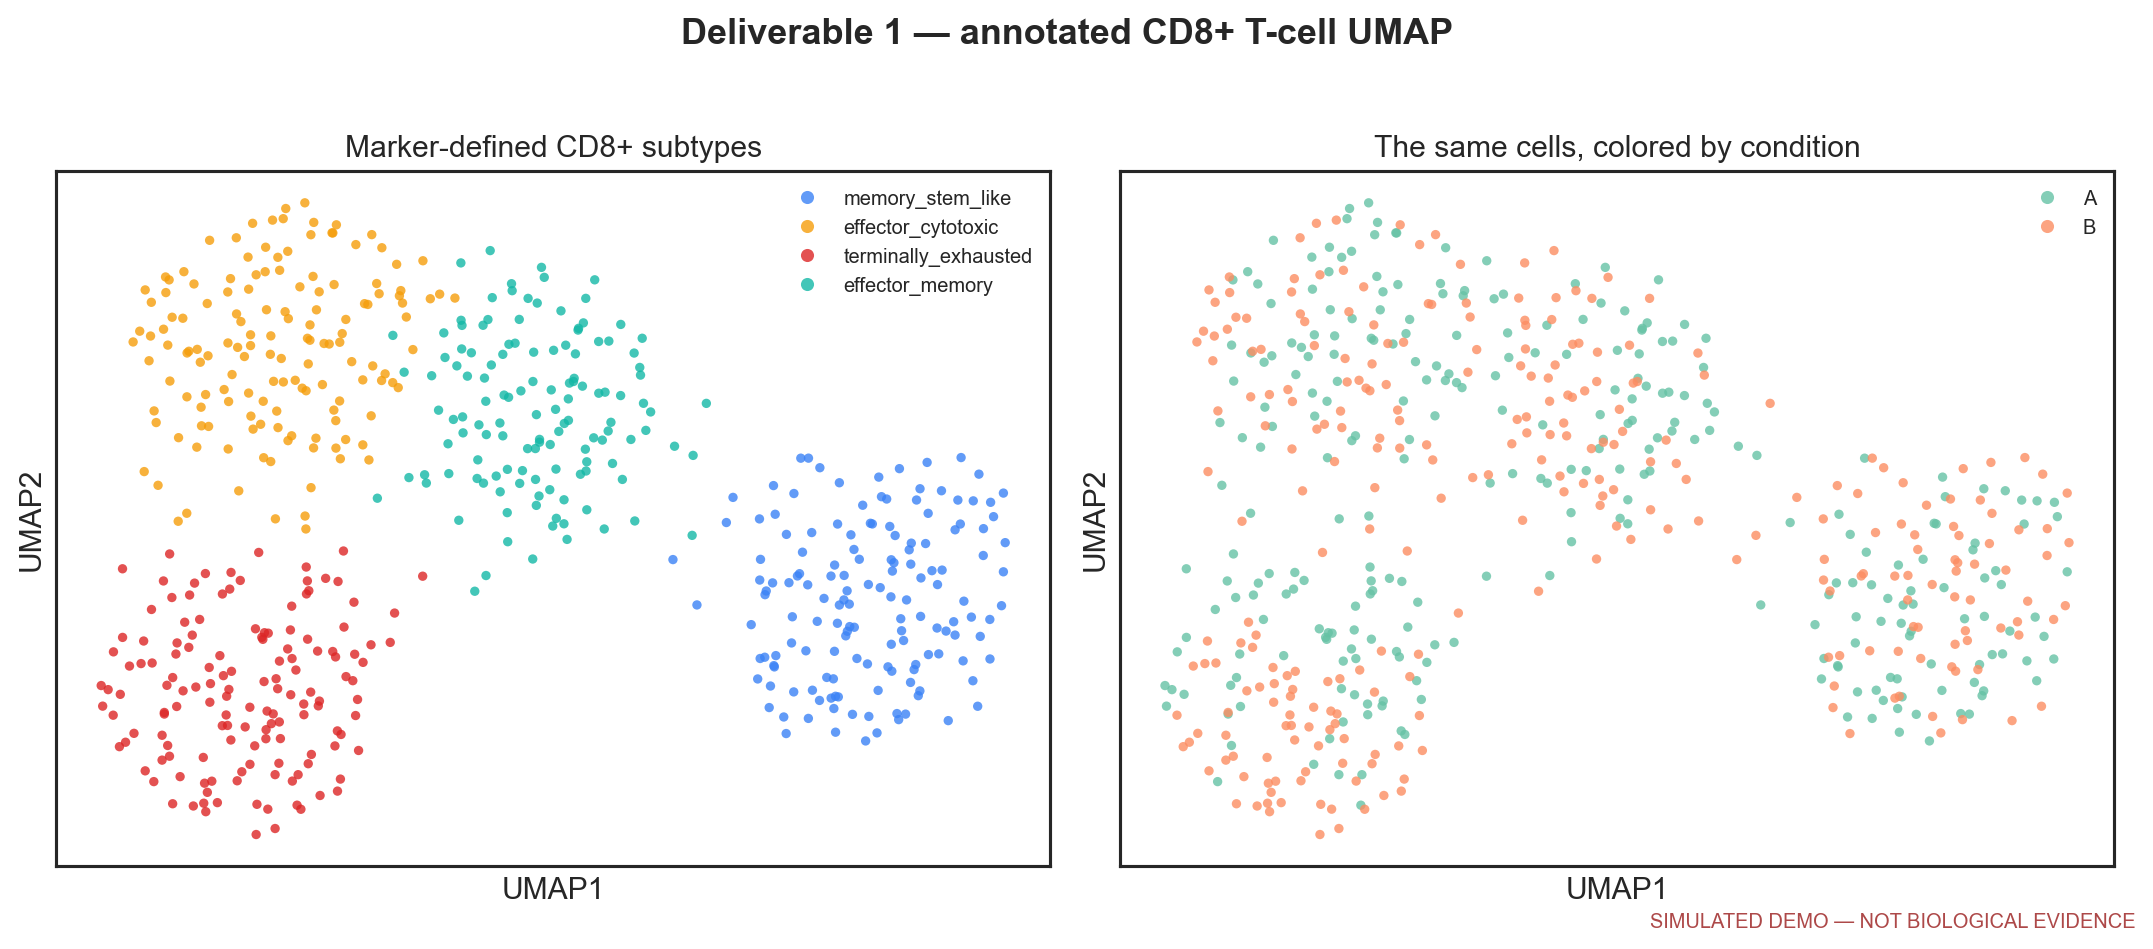

,resolution,cluster,subtype,marker_margin,n_cells,memory_stem_like,effector_cytotoxic,terminally_exhausted,effector_memory,effective_score__memory_stem_like,effective_score__effector_cytotoxic,effective_score__terminally_exhausted,effective_score__effector_memory,positive_markers_above_global__memory_stem_like,positive_markers_above_global__effector_cytotoxic,positive_markers_above_global__terminally_exhausted,positive_markers_above_global__effector_memory,negative_score__effector_memory
3,0.6,0,memory_stem_like,5.718,148,4.628,-1.878,-1.089,0.489,4.628,-1.878,-1.089,-inf,4,0,0,1,-1.002
4,0.6,1,effector_cytotoxic,2.535,145,-1.498,3.221,-0.404,0.686,-1.498,3.221,-0.404,0.686,0,4,0,2,-1.189
5,0.6,2,terminally_exhausted,4.990,143,-2.477,-1.044,3.946,-3.009,-2.477,-1.044,3.946,-inf,0,3,5,1,2.147
6,0.6,3,effector_memory,2.230,128,0.402,0.472,0.282,2.702,0.402,0.472,0.282,2.702,2,3,3,3,-0.896


In [26]:
display(Image(filename=OUTPUT_DIR / "figures" / "02_annotated_cd8_umap.png", width=1050))
annotations = pd.read_csv(OUTPUT_DIR / "tables" / "cluster_annotation_scores.csv")
display(annotations.query("resolution == 0.6").round(3))


## Step 7 — Exhaustion module and donor-aware violin (deliverable 2)

The module score asks whether the six genes move together relative to expression-matched control
genes. It is a **relative score**, not a concentration or clinical cutoff. The violin shape shows
cells; the outlined dots show the donor means that enter the test.

The table controls FDR across subtype comparisons. Our exact headline rule is: positive B−A
delta, FDR below 0.05, then choose the largest delta.


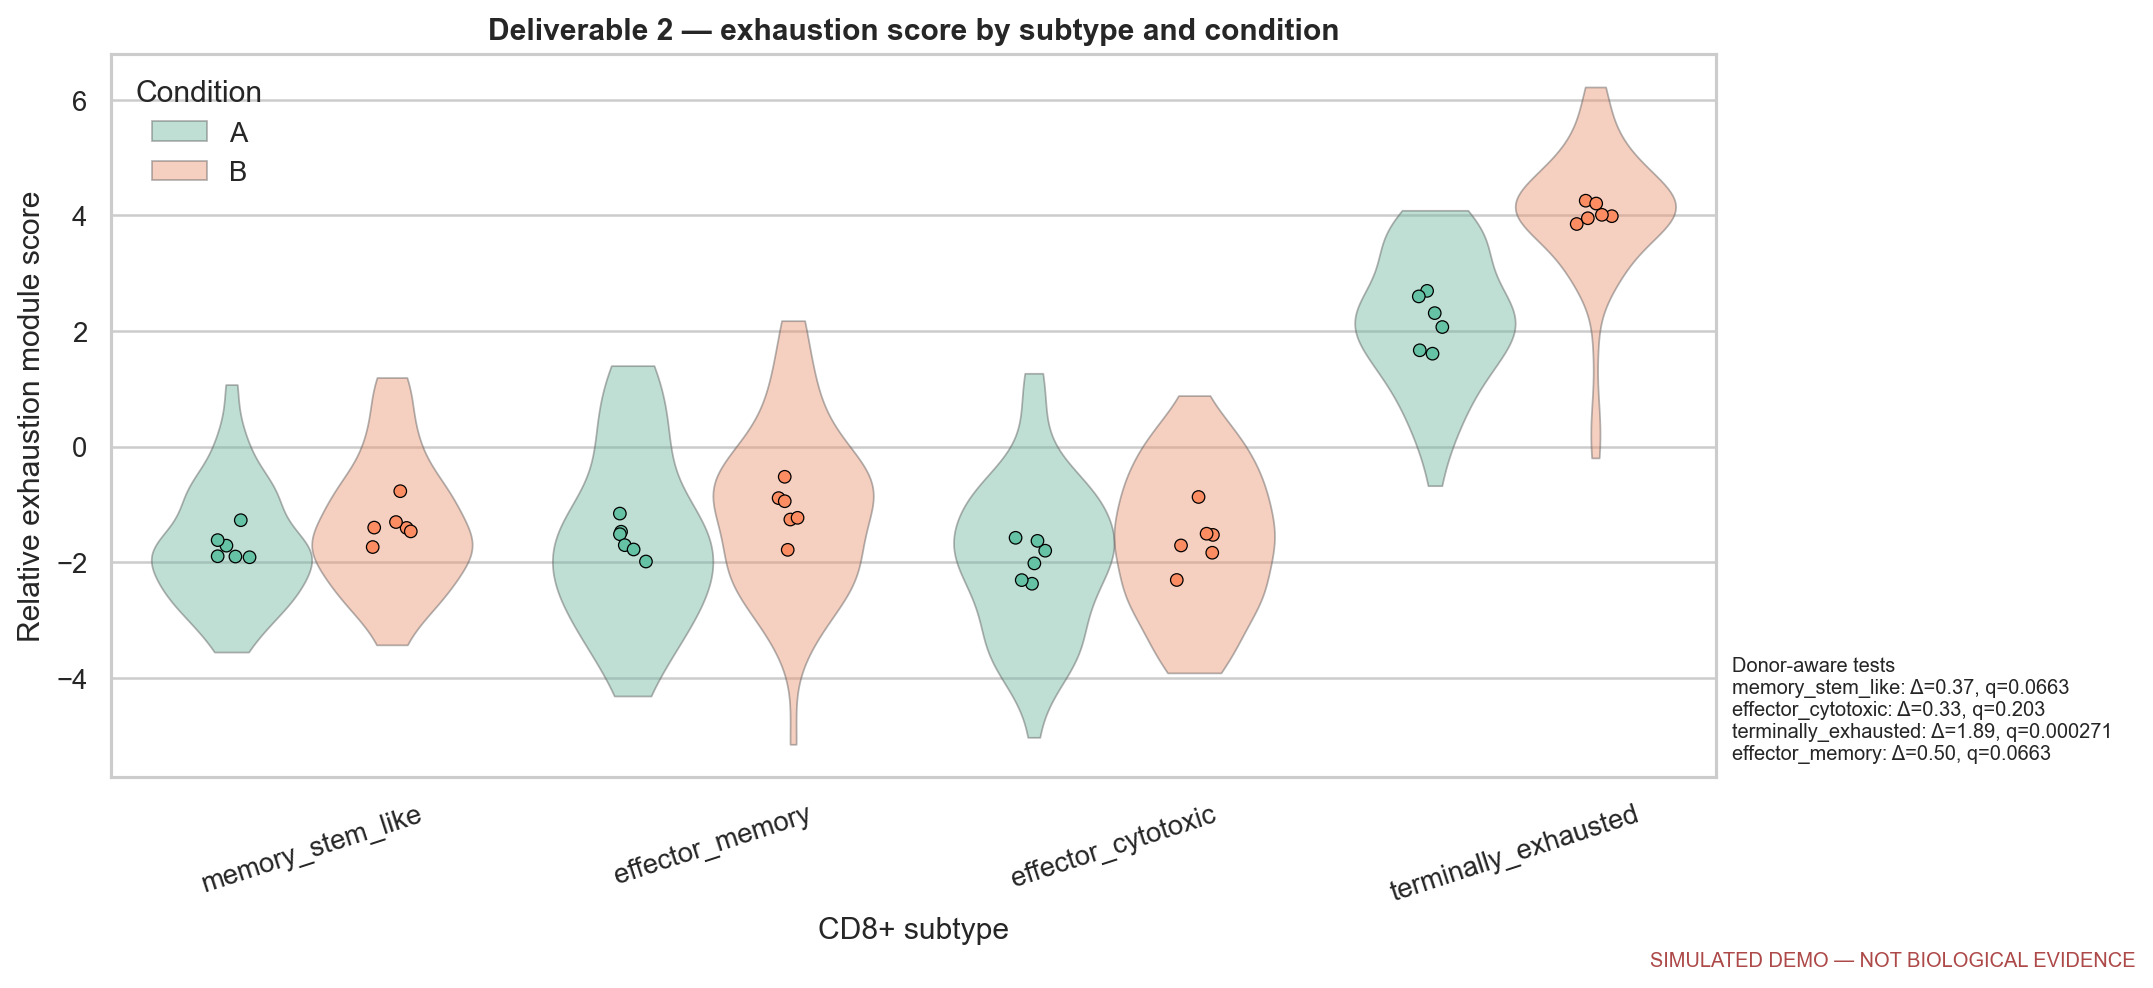

,subtype,delta,n_donors_a,n_donors_b,p_adj,test_status
0,memory_stem_like,0.3717,6,6,0.0663,NOT_SIGNIFICANT
1,effector_cytotoxic,0.3255,6,6,0.2027,NOT_SIGNIFICANT
2,terminally_exhausted,1.8863,6,6,0.0003,SIGNIFICANT
3,effector_memory,0.4972,6,6,0.0663,NOT_SIGNIFICANT


In [27]:
display(Image(filename=OUTPUT_DIR / "figures" / "03_exhaustion_violin.png", width=1050))
module_stats = pd.read_csv(OUTPUT_DIR / "tables" / "donor_exhaustion_statistics.csv")
display(module_stats[["subtype", "delta", "n_donors_a", "n_donors_b", "p_adj", "test_status"]].round(4))


### Exercise 2 — state the result without overclaiming

Complete this sentence in your own words:

> In the simulated dataset, ______ had the largest B−A exhaustion-score change (Δ=____,
> donor-level FDR=____). This was computationally ______, not experimentally ______.


In [28]:
headline = module_stats.sort_values("delta", ascending=False).iloc[0]
exercise_2 = (
    f"In the simulated dataset, {headline.subtype} had the largest B−A score change "
    f"(Δ={headline.delta:.2f}, donor-level FDR={headline.p_adj:.3g}). "
    "This was computationally corroborated, not experimentally validated."
)
exercise_2


'In the simulated dataset, terminally_exhausted had the largest B−A score change (Δ=1.89, donor-level FDR=0.000271). This was computationally corroborated, not experimentally validated.'

## Step 8 — Pseudobulk and the volcano (deliverable 3)

Pseudobulk restores the experimental unit by summing raw counts per donor × subtype. PyDESeq2 then
models the resulting count matrix. The volcano shows every tested gene; the six red genes were
pre-registered as the exhaustion panel.

- x-axis: estimated log2 fold-change, B versus A;
- y-axis: −log10(FDR), so higher means stronger adjusted evidence;
- right side: higher in B;
- horizontal line: FDR 0.05.

Large effect is not automatically reliable; low counts or donor variability can increase
uncertainty.


,sample_id,donor,condition,n_cells
0,A_donor_01__A,A_donor_01,A,13
1,A_donor_02__A,A_donor_02,A,13
2,A_donor_03__A,A_donor_03,A,12
3,A_donor_04__A,A_donor_04,A,10
4,A_donor_05__A,A_donor_05,A,10
5,A_donor_06__A,A_donor_06,A,10
6,B_donor_01__B,B_donor_01,B,12
7,B_donor_02__B,B_donor_02,B,12


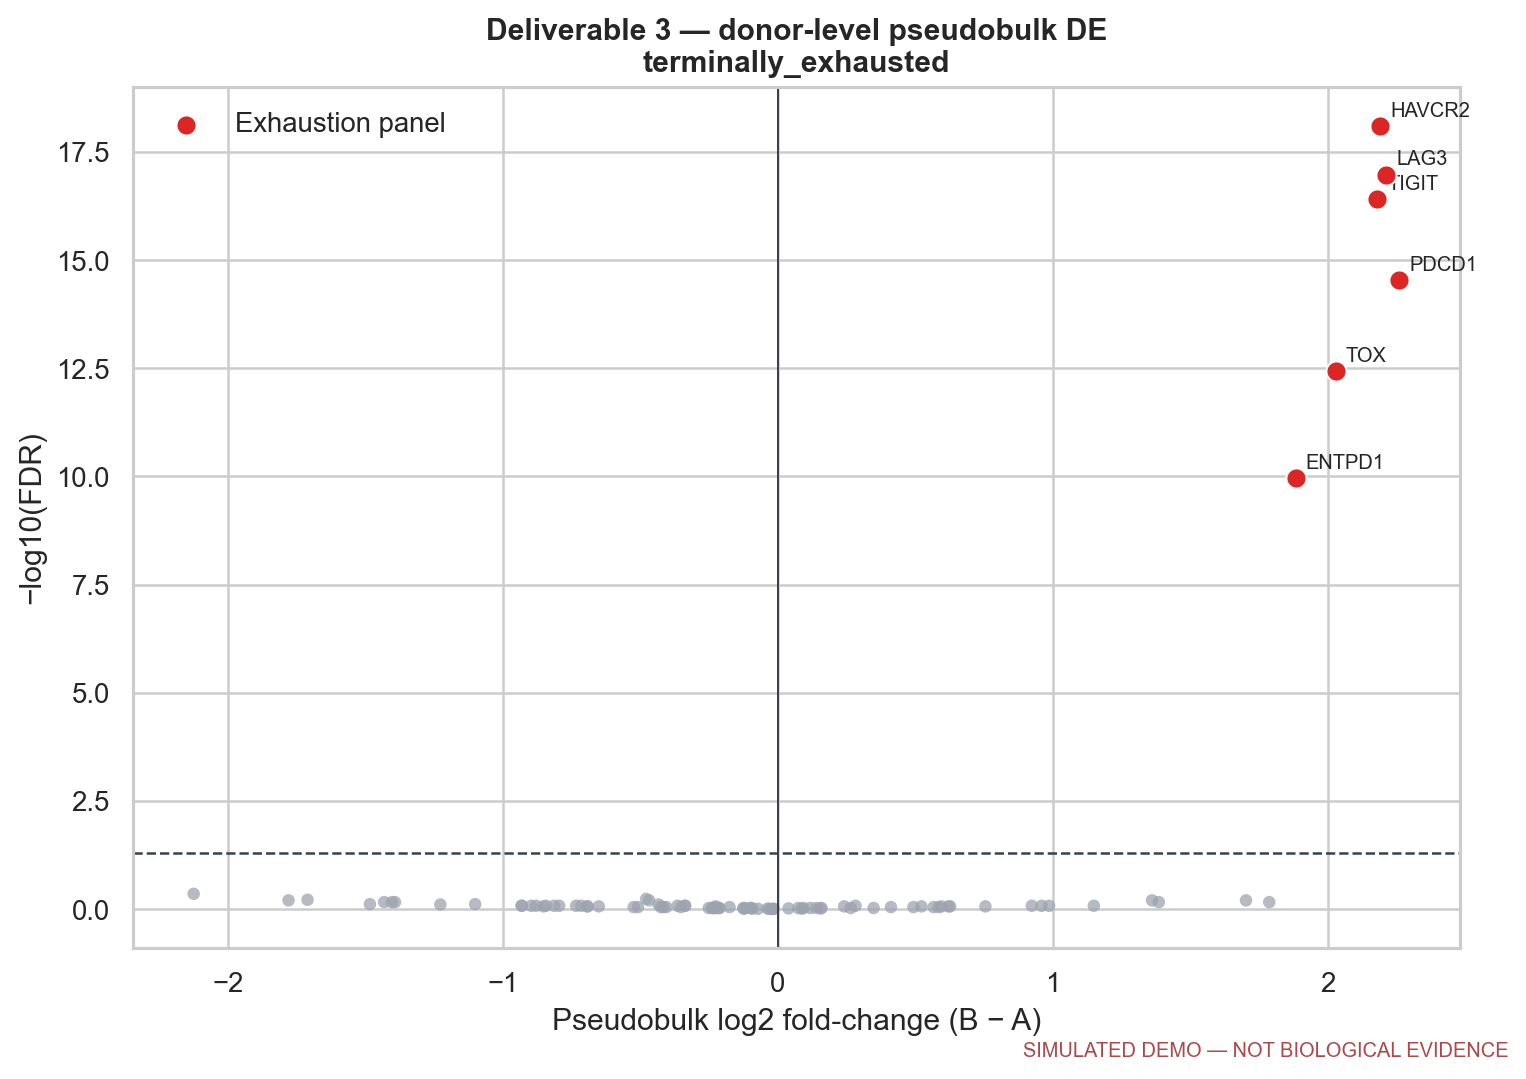

In [29]:
samples = pd.read_csv(OUTPUT_DIR / "tables" / "pseudobulk_sample_manifest.csv")
display(samples.head(8))
display(Image(filename=OUTPUT_DIR / "figures" / "04_pseudobulk_volcano.png", width=850))


## Step 9 — Reviewer-in-the-loop

The reviewer is an independent recomputation, not another model saying “looks good.” It ranks up
to 30 naive per-cell hits, joins the donor-level result, checks direction and FDR, then consults an
explicit evidence record.

- `SURVIVES`: matching non-zero direction and pseudobulk FDR < 0.05;
- `DOES_NOT_SURVIVE`: donor estimate exists but does not meet the rule;
- `DIRECTION_REVERSES`: donor direction is opposite;
- `NOT_TESTABLE`: evidence needed for a donor test is absent;
- `VERIFIED`: `SURVIVES` plus explicit literature and target plausibility approval.

Losing significance is not proof that a gene is biologically false; it means this dataset did not
provide enough donor-level evidence under the registered rule.


In [30]:
reviewer = pd.read_csv(OUTPUT_DIR / "tables" / "reviewer_findings.csv")
columns = [
    "gene", "per_cell_p_adj", "pseudobulk_p_adj", "pseudoreplication_delta_log10",
    "status", "evidence_pass", "final_status",
]
display(reviewer[columns].head(15))
reviewer["status"].value_counts().rename("genes").to_frame()


,gene,per_cell_p_adj,pseudobulk_p_adj,pseudoreplication_delta_log10,status,evidence_pass,final_status
0,HAVCR2,5.028394e-10,7.995392e-19,-8.798590,SURVIVES,True,VERIFIED
1,PDCD1,5.028394e-10,2.911792e-15,-5.237269,SURVIVES,True,VERIFIED
2,LAG3,2.354162e-09,1.069698e-17,-8.342575,SURVIVES,True,VERIFIED
3,TIGIT,9.851350e-09,3.915716e-17,-8.400685,SURVIVES,True,VERIFIED
4,ENTPD1,7.773347e-08,1.101691e-10,-2.848548,SURVIVES,True,VERIFIED
5,TOX,1.320124e-07,3.698014e-13,-5.552646,SURVIVES,True,VERIFIED
6,LAYN,3.502818e-05,5.784349e-01,4.217837,DOES_NOT_SURVIVE,False,NOT_VERIFIED
7,RPLP0,6.959297e-05,6.259671e-01,3.953986,DOES_NOT_SURVIVE,False,NOT_VERIFIED
8,GAPDH,3.265950e-04,7.816670e-01,3.379012,DOES_NOT_SURVIVE,False,NOT_VERIFIED
9,TRBC1,6.285812e-04,8.617587e-01,3.137024,DOES_NOT_SURVIVE,False,NOT_VERIFIED


,genes
status,
DOES_NOT_SURVIVE,17
SURVIVES,6
DIRECTION_REVERSES,4
NOT_TESTABLE,3


## Step 10 — Resolution robustness (deliverable 4)

Clustering resolution is a knob. A result that appears only at one convenient setting is fragile.
We registered `0.4, 0.6, 0.8, 1.0` in advance, reapplied the same annotation rule, and recomputed
the donor-level result each time.

Robust here means the **same headline subtype** keeps a matching direction and FDR below 0.05 at
all four settings. This checks one form of sensitivity; it does not make the conclusion universal.


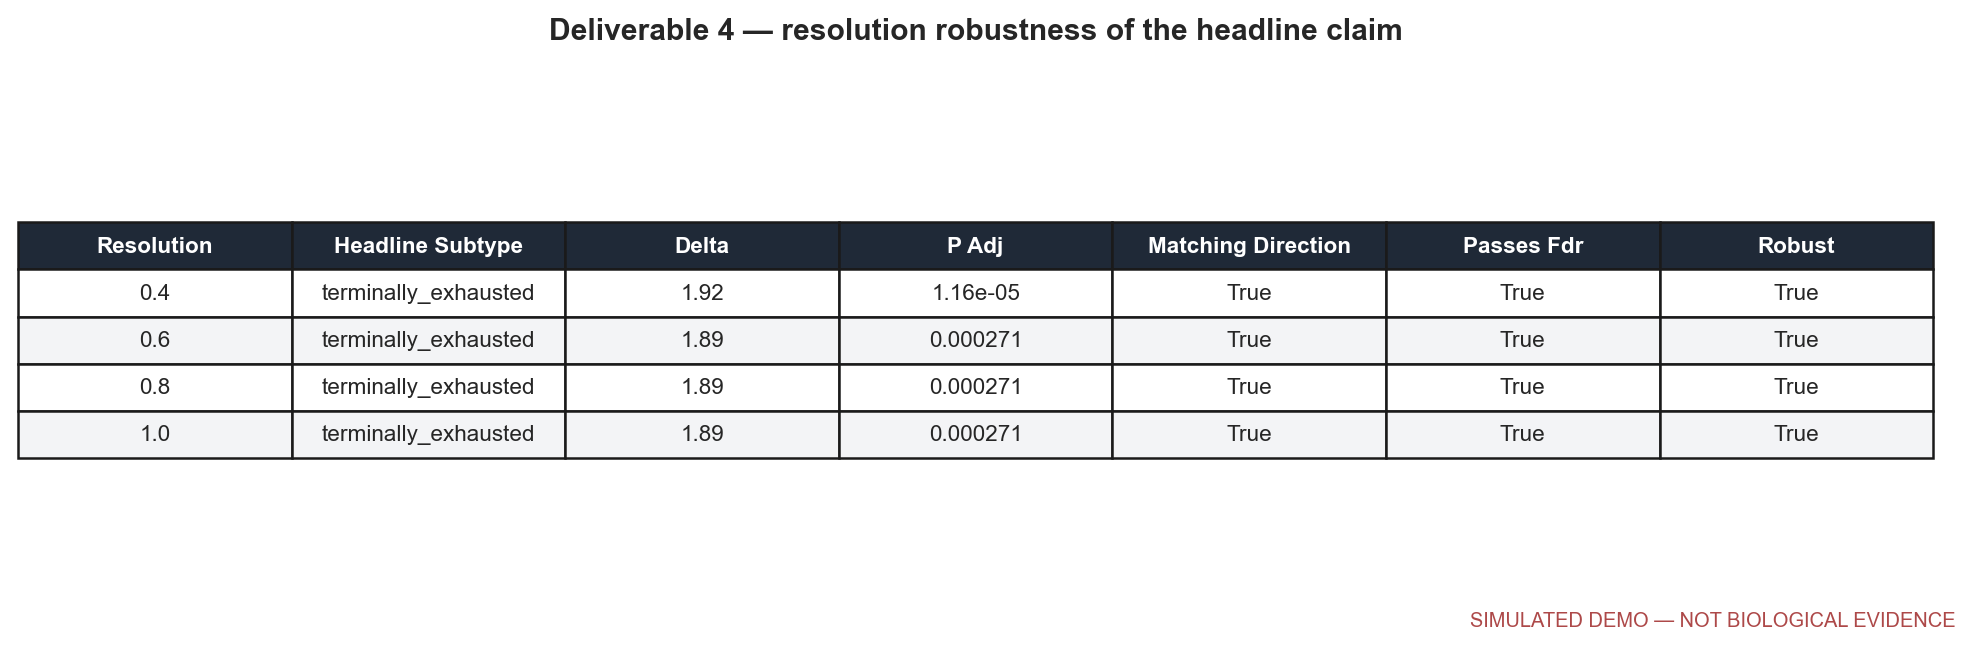

,resolution,headline_subtype,n_donors_a,n_donors_b,delta,p_adj,matching_direction,passes_fdr,robust
0,0.4,terminally_exhausted,6,6,1.922330,0.000012,True,True,True
1,0.6,terminally_exhausted,6,6,1.886305,0.000271,True,True,True
2,0.8,terminally_exhausted,6,6,1.886305,0.000271,True,True,True
3,1.0,terminally_exhausted,6,6,1.886305,0.000271,True,True,True


In [31]:
display(Image(filename=OUTPUT_DIR / "figures" / "05_resolution_robustness.png", width=1000))
robustness = pd.read_csv(OUTPUT_DIR / "tables" / "resolution_robustness.csv")
assert robustness["robust"].all()
robustness


## Step 11 — External evidence is separate from the data result

The CSV below is intentionally human-auditable. A citation must support the gene/context note; a
URL alone is not evidence. The Open Targets record establishes target-level plausibility, not that
the gene causes the observed condition contrast. Context—species, tissue, disease, treatment, and
assay—still matters.


In [32]:
evidence = pd.read_csv(EVIDENCE_PATH)
display(evidence[["gene", "literature_pass", "target_pass", "citation", "context_scope"]])


,gene,literature_pass,target_pass,citation,context_scope
0,PDCD1,True,True,"Blackburn et al., Nature Immunology 2009, PMID...","general exhaustion plausibility, not dataset-s..."
1,HAVCR2,True,True,"Sakuishi et al., Journal of Experimental Medic...",tumor models; check transferability
2,LAG3,True,True,"Blackburn et al., Nature Immunology 2009, PMID...",chronic viral infection
3,TOX,True,True,"Khan et al., Nature 2019, PMID 31207603",mouse chronic infection and cancer with human ...
4,TIGIT,True,True,"Johnston et al., Cancer Cell 2014, PMID 25465800",cancer and chronic viral models
5,ENTPD1,True,True,"Canale et al., Cancer Research 2018, PMID 2906...",tumor microenvironment


## Common pitfalls and how this project handles them

| Pitfall | Guardrail |
|---|---|
| Treating cells as independent people | Average/sum to donor × subtype before inference. |
| Normalizing counts before pseudobulk | Preserve and sum `layers['counts']` only. |
| Picking markers/resolution after seeing the answer | Write the analysis contract first. |
| Calling UMAP islands proof | Use marker scores and donor-level tests; describe UMAP as visualization. |
| Correcting FDR only over six favorite genes | Test/correct across all genes; highlight the panel afterward. |
| Calling a nonsignificant hit “refuted” | Say it did not survive this registered donor-level check. |
| Calling in-silico evidence “validated” | Reserve validated for orthogonal wet-lab confirmation. |
| One-condition marker fallback | Keep it descriptive; defining and testing exhaustion with the same genes is circular. |


## Step 12 — Read the generated answer and provenance

The pipeline writes the exact methods, a result-first report, a three-minute script, and SHA-256
checksums/package versions. This makes the claim traceable to the input and analysis contract.


In [33]:
display(Markdown((OUTPUT_DIR / "report.md").read_text(encoding="utf-8")))
manifest = json.loads((OUTPUT_DIR / "provenance" / "manifest.json").read_text(encoding="utf-8"))
display(pd.Series(manifest["package_versions"], name="version").to_frame())


# Verified CD8+ T-cell Exhaustion Triage — Run Report

> **SIMULATED DEMO — NOT BIOLOGICAL EVIDENCE.** This report proves the workflow, not a
> claim about patients, disease, or treatment.

## Answer first

The largest positive donor-level exhaustion-score shift was in **terminally_exhausted** (B − A = 1.886, FDR = 0.000271). The direction and FDR criterion held across every registered resolution.

The reviewer audited 30 fast per-cell hits: 6 survived donor-level
recomputation and 6 also had explicit external-evidence approval. A surviving
statistical hit without reviewed external evidence is **not verified**.

## What was analyzed

- Input: `C:\Users\miqba\projects\claude-science-hackathon-learning-plan\data\tutorial_demo.h5ad`
- Cells / genes before filtering: 648 / 118
- Contrast: B versus A
- Statistical branch: `donor_aware` — Donors were available, so donor-level inference and the reviewer loop were enabled.
- Required genes missing: none

## How to read the deliverables

1. **Annotated UMAP:** local neighbors with similar expression should group, and labels should be
   supported by markers. UMAP spacing is not an effect size or a p-value.
2. **Exhaustion violin:** the translucent shape shows cells; overlaid points show donor means.
   The donor count—not the cell count—is the independent sample size.
3. **Volcano:** rightward genes increase in B; height is donor-level FDR evidence. Red points are
   the pre-registered exhaustion panel, but FDR was corrected across every tested gene.
4. **Robustness table:** a claim is robust only when its direction and FDR criterion survive all
   four pre-registered Leiden resolutions.
5. **Reviewer table:** `SURVIVES` means the fast cell-level hit agrees with donor pseudobulk;
   `VERIFIED` additionally requires reviewed PubMed/Open Targets evidence.

## Headline subtype table

| subtype              | condition_a   | condition_b   |   mean_a |   mean_b |    delta |   n_units_a |   n_units_b |   n_donors_a |   n_donors_b |   t_statistic |     p_value | donor_aware   | analysis_unit   |       p_adj | significant   | test_status     |
|:---------------------|:--------------|:--------------|---------:|---------:|---------:|------------:|------------:|-------------:|-------------:|--------------:|------------:|:--------------|:----------------|------------:|:--------------|:----------------|
| memory_stem_like     | A             | B             | -1.72103 | -1.34937 | 0.371664 |           6 |           6 |            6 |            6 |       2.24873 | 0.0497138   | True          | donor mean      | 0.066285    | False         | NOT_SIGNIFICANT |
| effector_cytotoxic   | A             | B             | -1.95344 | -1.62799 | 0.325458 |           6 |           6 |            6 |            6 |       1.37298 | 0.202678    | True          | donor mean      | 0.202678    | False         | NOT_SIGNIFICANT |
| terminally_exhausted | A             | B             |  2.15784 |  4.04415 | 1.88631  |           6 |           6 |            6 |            6 |       9.51606 | 6.78077e-05 | True          | donor mean      | 0.000271231 | True          | SIGNIFICANT     |
| effector_memory      | A             | B             | -1.60457 | -1.10736 | 0.497212 |           6 |           6 |            6 |            6 |       2.3628  | 0.0431895   | True          | donor mean      | 0.066285    | False         | NOT_SIGNIFICANT |

## Resolution robustness

|   resolution | headline_subtype     |   n_donors_a |   n_donors_b |   delta |       p_adj | matching_direction   | passes_fdr   | robust   |
|-------------:|:---------------------|-------------:|-------------:|--------:|------------:|:---------------------|:-------------|:---------|
|          0.4 | terminally_exhausted |            6 |            6 | 1.92233 | 1.16254e-05 | True                 | True         | True     |
|          0.6 | terminally_exhausted |            6 |            6 | 1.88631 | 0.000271231 | True                 | True         | True     |
|          0.8 | terminally_exhausted |            6 |            6 | 1.88631 | 0.000271231 | True                 | True         | True     |
|          1   | terminally_exhausted |            6 |            6 | 1.88631 | 0.000271231 | True                 | True         | True     |

## Limitations

- This is observational RNA evidence and cannot establish causality or therapeutic benefit.
- In-silico corroboration is not qPCR, flow cytometry, or functional-assay validation.
- RNA dropout makes the CD8/CD4 gate imperfect; expert annotations should be compared when present.
- Marker-based subtype labels and module scores depend on the registered panels and data quality.
- Batch, tissue, treatment, and donor composition can confound a condition contrast.
- Literature presence is context-dependent plausibility, not proof that a gene drives this dataset.

See `methods.md`, `provenance/manifest.json`, and the teaching notebook for the exact workflow.


,version
anndata,0.12.19
igraph,1.0.0
leidenalg,0.11.0
matplotlib,3.10.9
numpy,2.4.6
pandas,2.3.3
pydeseq2,0.5.4
python,3.12.13
scanpy,1.12.2
scipy,1.18.0


## Use the real organizer dataset

1. Copy `configs/real-data.example.yaml` to a new file.
2. Read the data dictionary yourself. Map the condition, donor, and count-layer fields—do not guess.
3. Confirm the file is de-identified/licensed for this use and contains raw integer counts.
4. Lock QC thresholds and condition semantics before looking at the condition result.
5. Run `uv run tcell-triage inspect --config YOUR_CONFIG.yaml`.
6. Resolve every blocker/warning, then run:
   `uv run tcell-triage run --config YOUR_CONFIG.yaml --evidence evidence/literature_evidence.csv`.
7. Re-review every citation in the actual tissue/disease context and ask a domain expert to audit
   the annotation and claim.

Do not copy the simulated numerical answer into a real submission. The real data must earn its own
headline—or an honest null result.


## Final exercises and teach-back

Answer without looking at the earlier sections:

1. Why can 10,000 cells still represent only six independent replicates?
2. Which matrix is used for UMAP/module scoring, and which for pseudobulk?
3. What do the x and y axes of the volcano mean?
4. What exactly must happen before a row says `VERIFIED`?
5. Why is `VERIFIED` still not `VALIDATED`?
6. Name two reasons a robust simulated result might fail on real data.

Then explain the whole chain aloud from memory:

> input audit → QC/CD8 gate → normalization → clustering/annotation → exhaustion score → donor
> means → pseudobulk gene test → robustness sweep → external-evidence audit → qualified claim.

If any arrow feels fuzzy, return to that section. The ability to explain the chain is the learning
goal; running the code is only the scaffolding.


In [34]:
# Answer scaffold: write these in your own words before checking the notebook text.
teach_back = {
    "independence": "",
    "normalized_vs_raw": "",
    "volcano_axes": "",
    "verification_rule": "",
    "verification_boundary": "",
    "real_data_failure_modes": ["", ""],
}
teach_back


{'independence': '',
 'normalized_vs_raw': '',
 'volcano_axes': '',
 'verification_rule': '',
 'verification_boundary': '',
 'real_data_failure_modes': ['', '']}